# Evolution Simulation Germany
Germany serves as a reference with a temperate mild climate. 

In [1]:
import utils.param_loader as param_loader
import numpy as np

from utils.evolution import run_evolution_simulation
from utils.evolution_plotting import (
    plot_grouped_trait_dynamics,
    plot_delta13C_trajectory_clean,
    plot_3d_evolution_trajectory,
    plot_pareto_front,
    # plot_evolution_trajectory,
    plot_evolution_direction,
    plot_evolution_overview,
    plot_evolution_summary,
    plot_3d_evolution_interactive,
    plot_hybrid_evolution_view,
    _sanitize_history,
    # plot_fraction_fitness_map,
)

## Environmental Parameters
Soil type was set to `loam` and $\rho$<sub>soil</sub> was corrected accordingly.

In [2]:
# param_loader.store_api_parameters(set_name='germany', longitude = 8.0, latitude = 51.0, date='20230615')

In [3]:
params = param_loader.load_parameters(environmental_params='germany', soil_params='loam')
params['rho_soil'] = 0.15

## Evolvable Traits

In [4]:
evolving_traits = [
    "g_bs",  # bundle sheath conductance
    "g_m",  # mesophyll conductance
    "f_pepc",  # enzyme budget fraction for PEPC
    "f_rubisco_mes",  # enzyme budget fraction for mesophyll Rubisco
    "f_rubisco_bs",  # enzyme budget fraction for BS Rubisco
    "k_c",
    "k_o",
    "k_p",
]

bounds = [
    [0.0001, 0.1],  # g_bs
    [1, 6],  # g_m
    [0.0, 0.6],  # f_pepc (up to 60% for strong C4)
    [0.0, 0.9],  # f_rubisco_mes
    [0.0, 0.9],  # f_rubisco_bs
    [1000.0, 100000.0],  # k_c
    [7500.0, 27500000.0],  # k_o
    [1000.0, 70000000.0],  # k_p
]

initial_c3_like = {
    "g_bs": 0.0015,
    "g_m": 5.0,
    "f_pepc": 0.2,  # almost no PEPC
    "f_rubisco_mes": 0.7,  # mostly mesophyll Rubisco
    "f_rubisco_bs": 0.1,  # small BS Rubisco activity
    "k_c": 6500.0,
    "k_o": 2_000_000.0,
    "k_p": 500_0.0,
}

## Evolution Simulation

In [5]:
number_of_generations = 70
population_size = 30

In [6]:
initial_c3_like = {
    "g_bs": 0.0015,  # very low BS leakiness typical of C3 (tight barrier)
    "g_m": 5.0,  # high mesophyll conductance
    "f_pepc": 0.0,  # almost no PEPC
    "f_rubisco_mes": 0.990,  # mostly mesophyll Rubisco
    "f_rubisco_bs": 0.01,  # small BS Rubisco activity
    "k_c": 6500.0,  # Rubisco affinity typical of C3 (moderate)
    "k_o": 2000000.0,  # oxygen affinity typical of C3
    "k_p": 5000.0,  # PEPC affinity low (non-specialized enzyme)
}

In [7]:
loaded_history = run_evolution_simulation(
    evolving_traits=evolving_traits,
    bounds=bounds,
    base_params=params,
    n_generations=number_of_generations,
    pop_size=population_size,
    sigma0=1,  # Adjust as needed; higher = more exploration
    beta=1,
    initial_traits=initial_c3_like,  # you can set the initial start of the simulations
    verbose=False,
)

Hybrid evolution: 100%|██████████| 70/70 [00:56<00:00,  1.25it/s, mean_fit=28.98, best_fit=29.28, σ=0.05] 


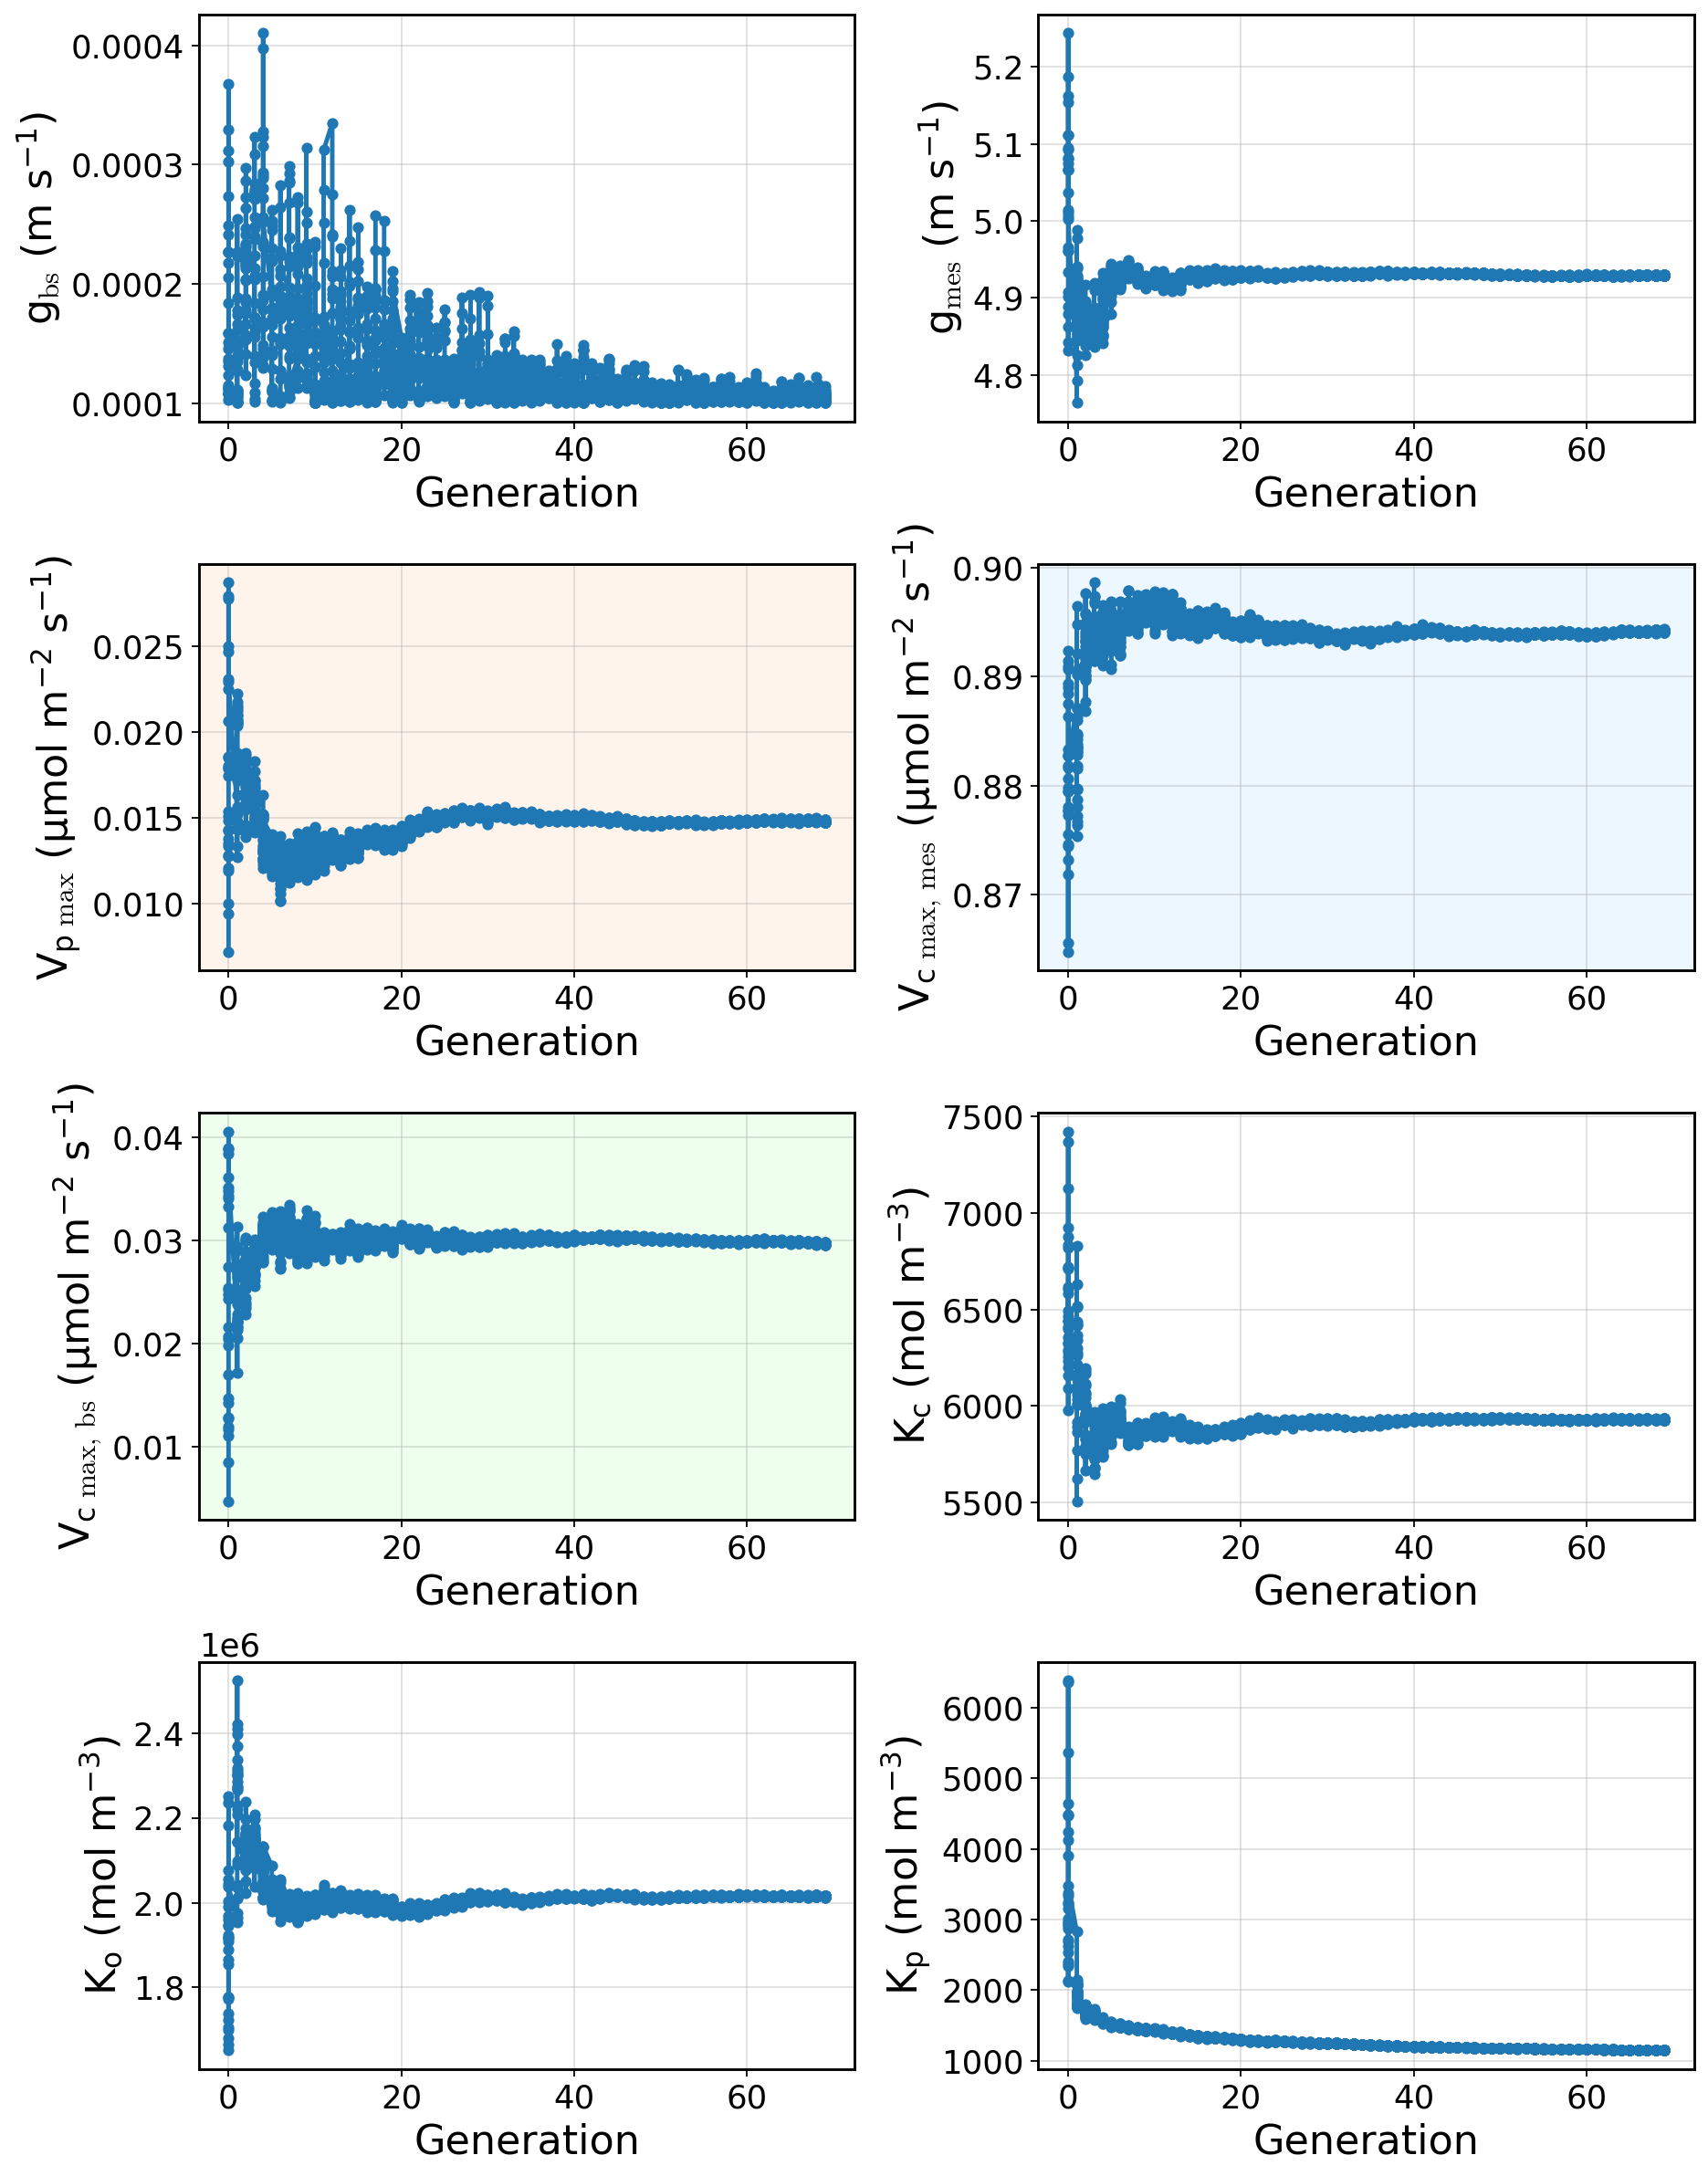

In [8]:
trait_names = [
    "$g_{\\text{bs}}$ (m s$^{-1}$)",
    "$g_{\\text{mes}}$ (m s$^{-1}$)",
    "$V_{p~\\max}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$V_{c~\\text{max, mes}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$V_{c~\\text{max, bs}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$K_c$ (mol m$^{-3}$)",
    "$K_o$ (mol m$^{-3}$)",
    "$K_p$ (mol m$^{-3}$)"
]

# Plot trait dynamics
plot_grouped_trait_dynamics(loaded_history["traits"], 
                            evolving_traits, 
                            trait_names, 
                            loaded_history["delta13C_generations"],
                            save_path="plots/evolution/germany/single_traits_germany.png")

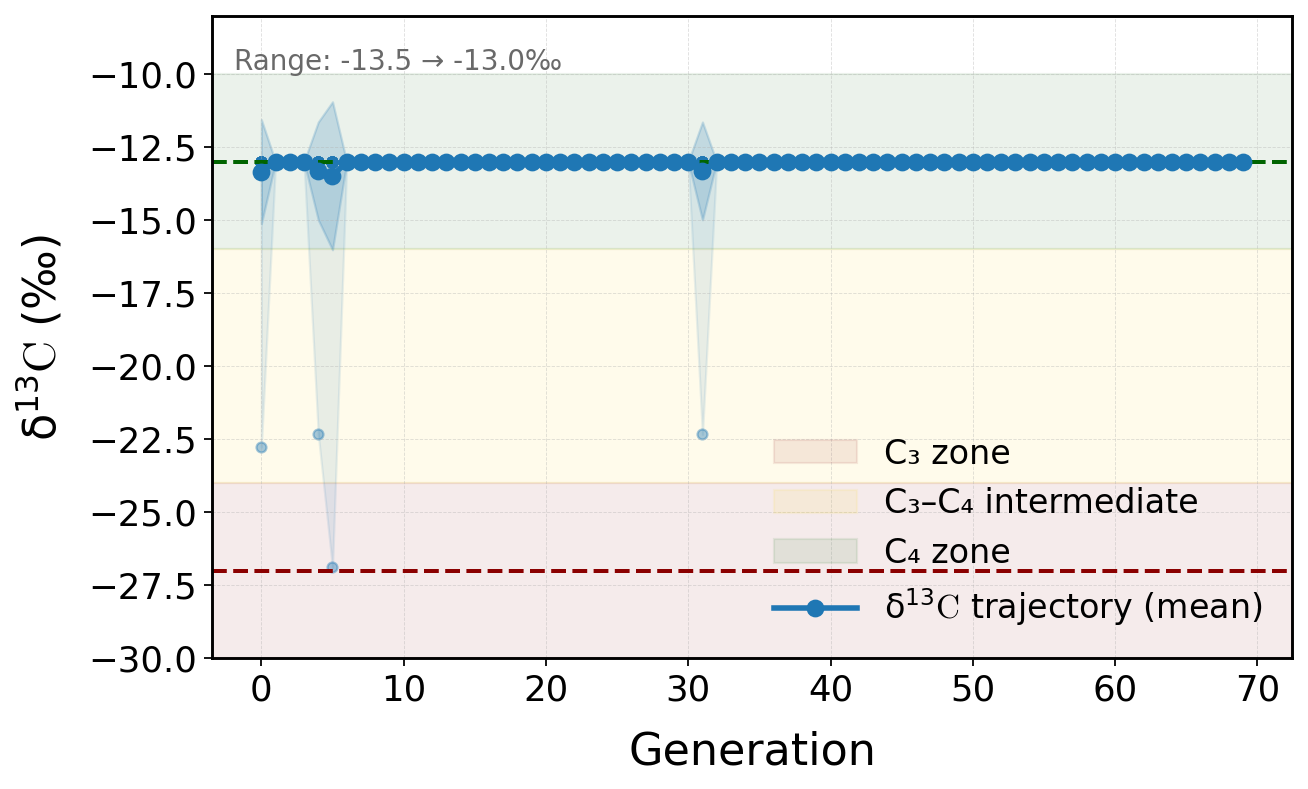

In [9]:
# Plot δ13C trajectory if valid data exists
if any(np.isfinite(d) for d in loaded_history["delta13C"]):
    plot_delta13C_trajectory_clean(
        loaded_history["delta13C"], 
        loaded_history["delta13C_generations"],
        save_path="plots/evolution/germany/delta13C_trajectory_germany.png"
    )
else:
    print("[INFO] No valid δ13C data to plot.")

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:416: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


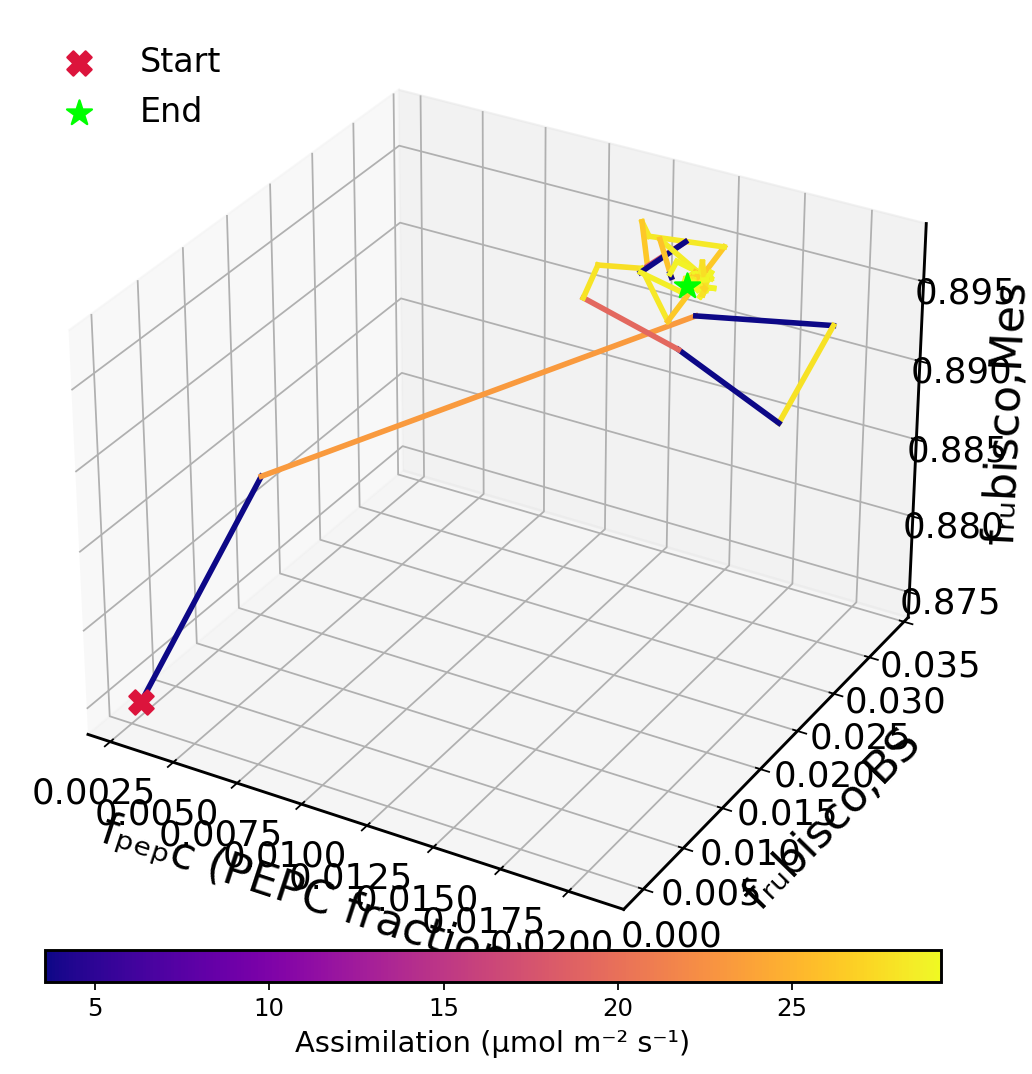

In [10]:
# Select elite individuals (e.g., top per generation or last generation)
elite_indices = list(
    range(
        0,
        len(loaded_history["traits"]),
        len(loaded_history["traits"]) // number_of_generations,
    )
)
elite_traits = [loaded_history["traits"][i] for i in elite_indices]
elite_fitness = [loaded_history["fitness"][i] for i in elite_indices]

# 3D evolution trajectory

plot_3d_evolution_trajectory(
    trait_history=elite_traits,
    fitness_history=elite_fitness,
    save_path="plots/evolution/germany/3d_evolution_trajectory_germany.png",
    cmap_name="plasma",  # or "viridis", "inferno", etc.
)

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:520: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


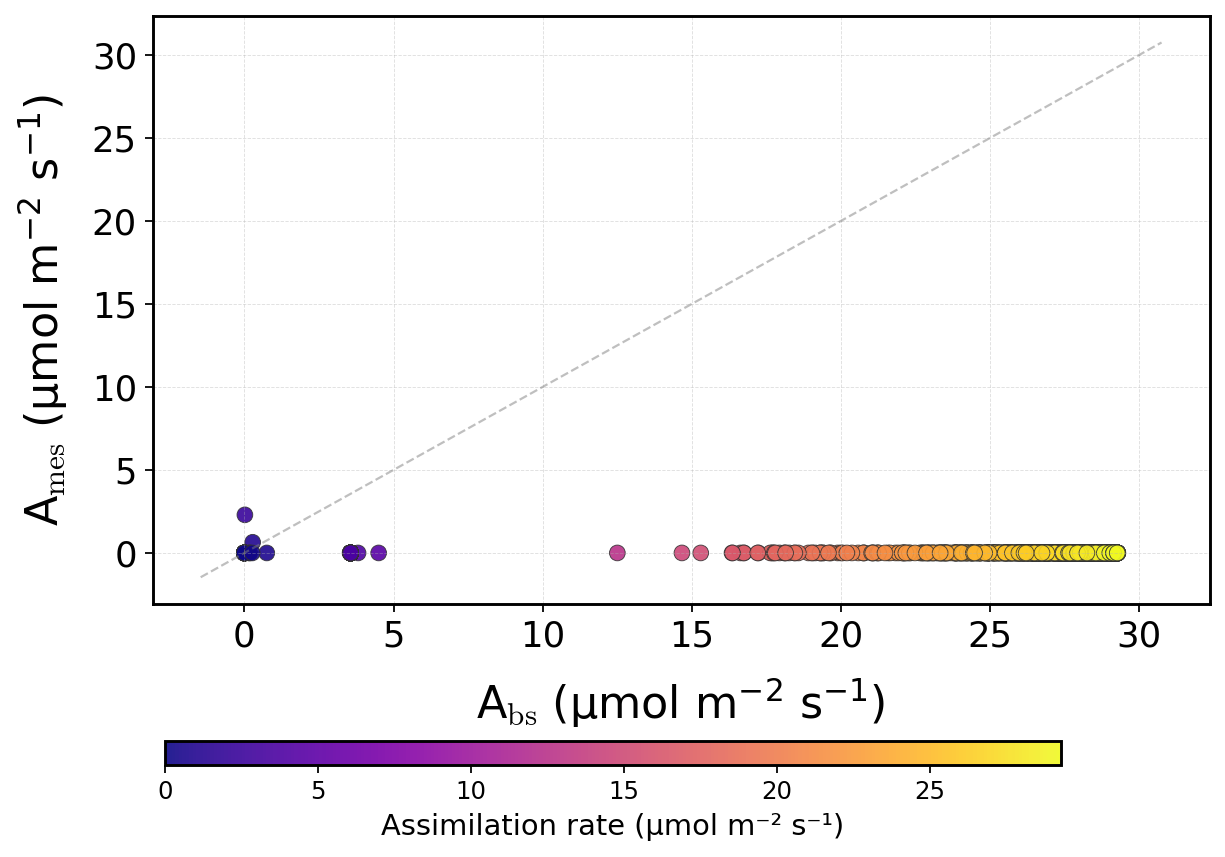

In [11]:
def safe_extract(lst, idx):
    """Safely get element at index, else np.nan."""
    return lst[idx] if idx < len(lst) else np.nan

# Pareto front plot
plot_pareto_front(
    fitness_bs=[
        safe_extract(loaded_history["fitness_bs"], i)
        for i in range(0, len(loaded_history["fitness_bs"]))
    ],
    fitness_mes=[
        safe_extract(loaded_history["fitness_mes"], i)
        for i in range(0, len(loaded_history["fitness_mes"]))
    ],
    save_path="plots/evolution/germany/pareto_front_germany.png"
)

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:416: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


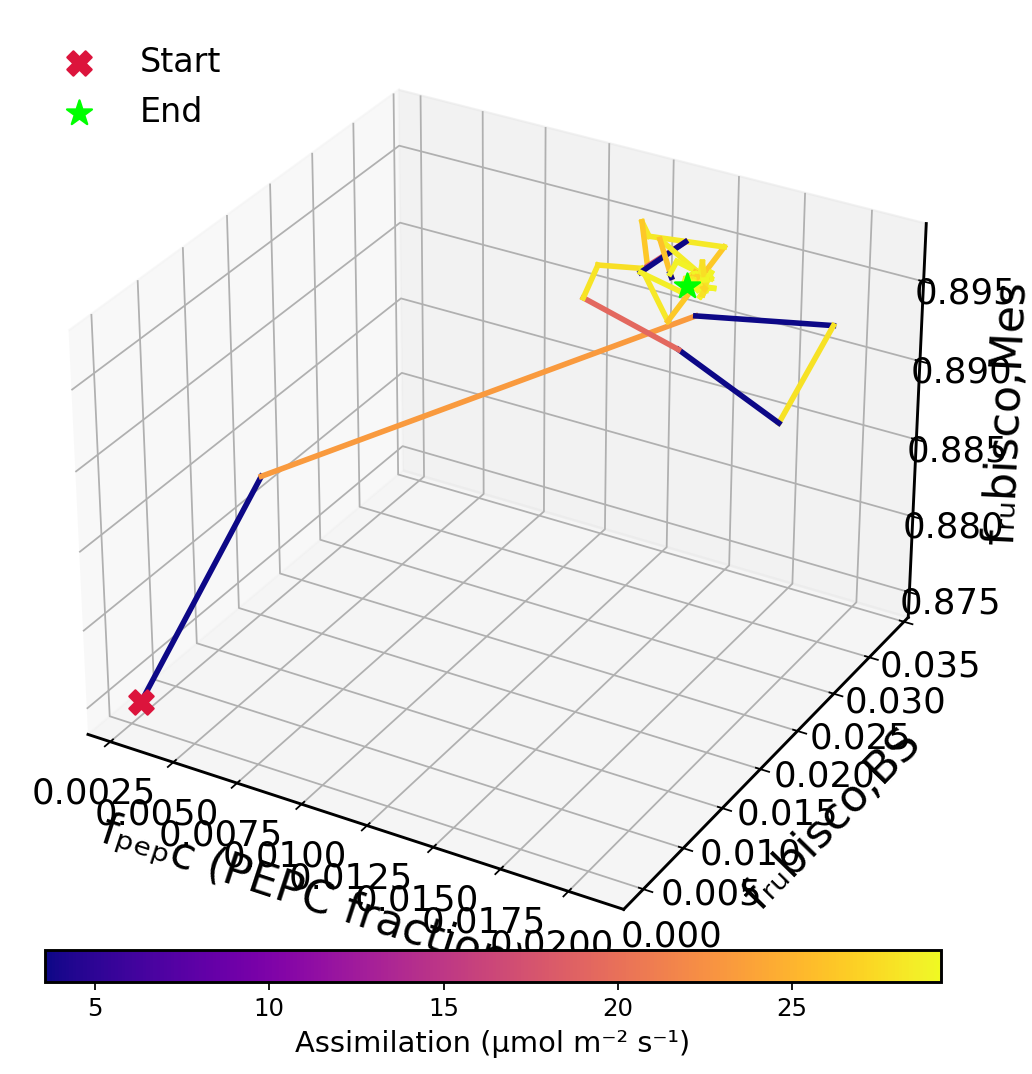

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:520: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


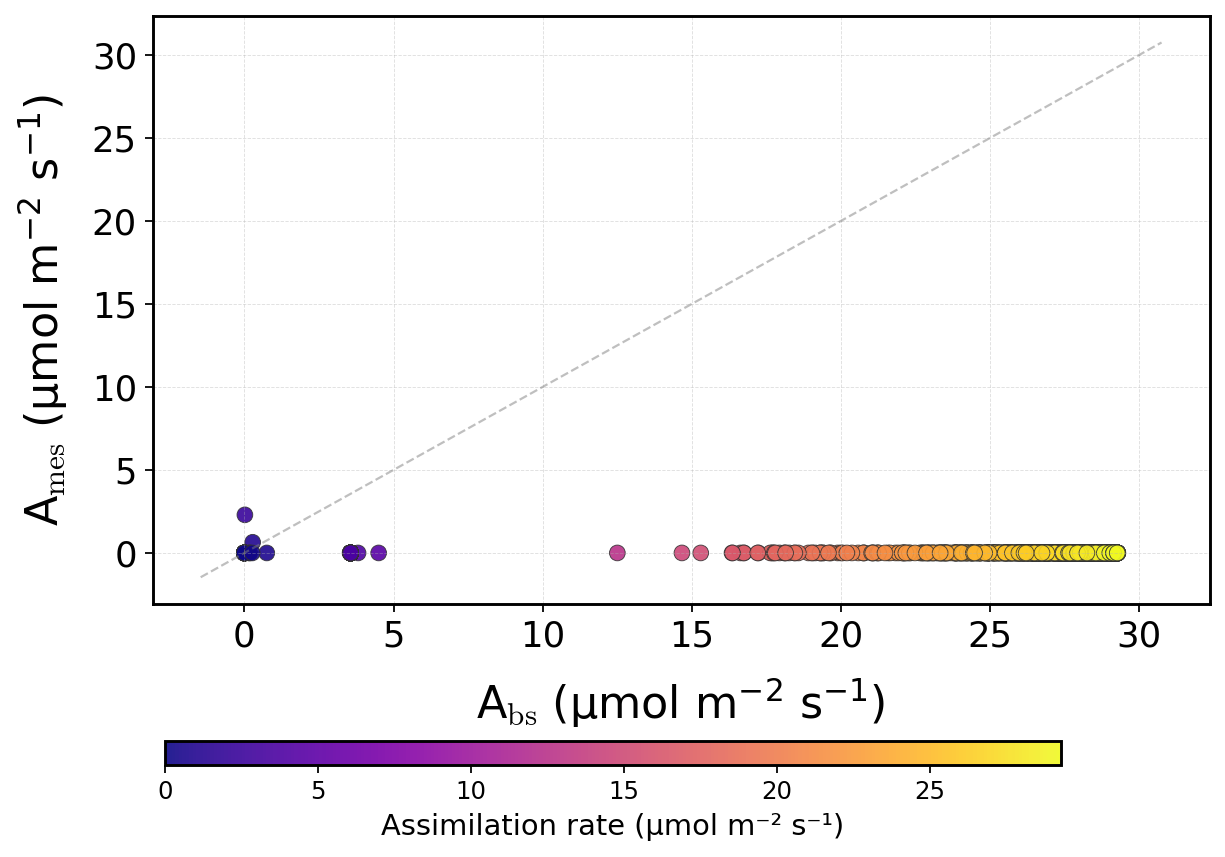

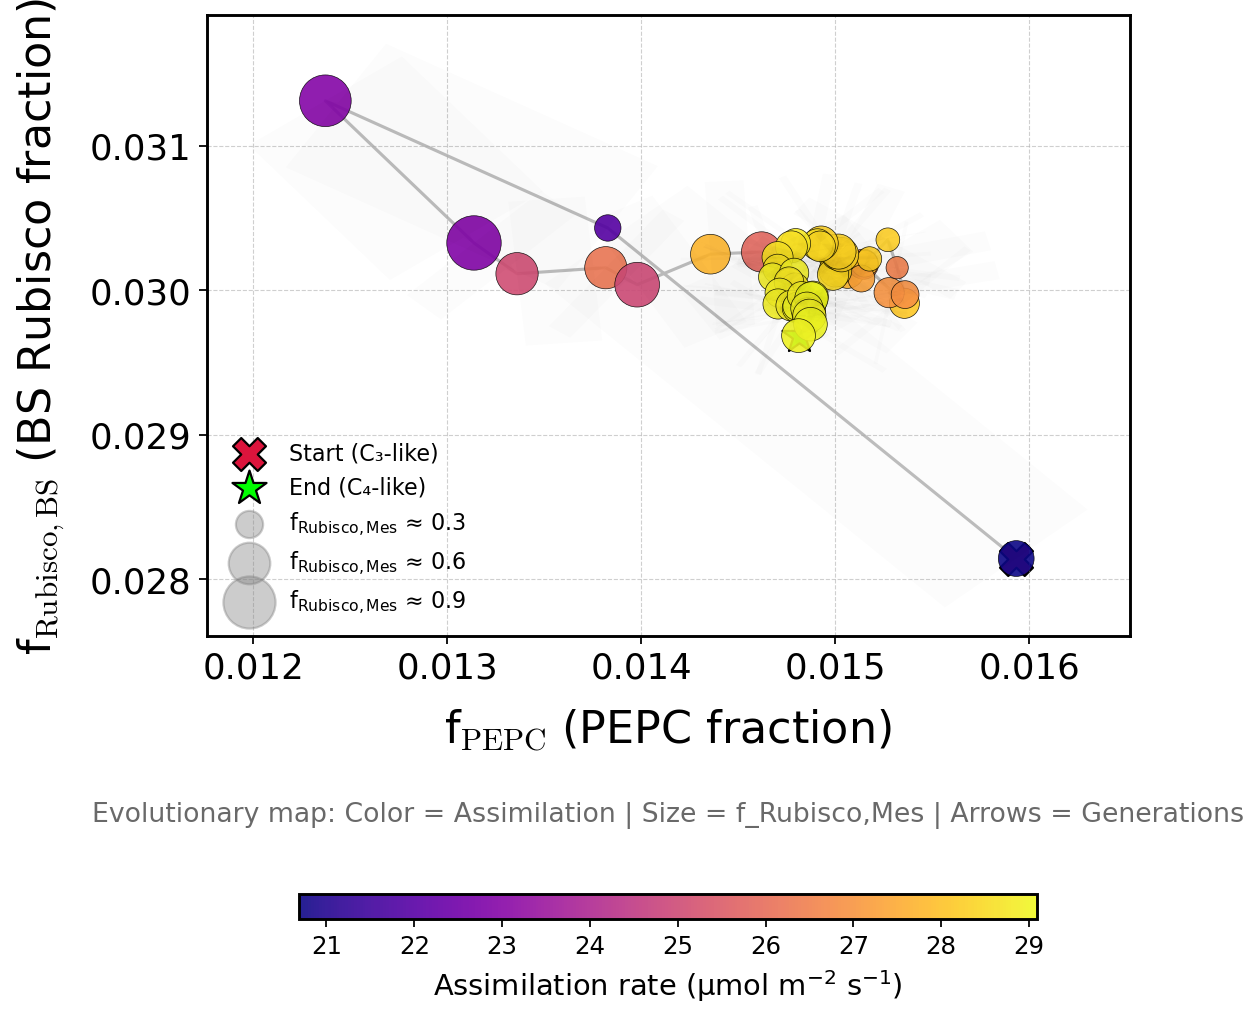

⚠️ No valid (finite) values found for v_cmax_mes vs v_cmax_bs.


In [12]:
loaded_history = _sanitize_history(loaded_history)

plot_3d_evolution_trajectory(elite_traits, elite_fitness)
plot_pareto_front(loaded_history["fitness_bs"], loaded_history["fitness_mes"])
plot_evolution_overview(loaded_history)
plot_evolution_direction(loaded_history, "v_cmax_mes", "v_cmax_bs")

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:891: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 1, 0.96])


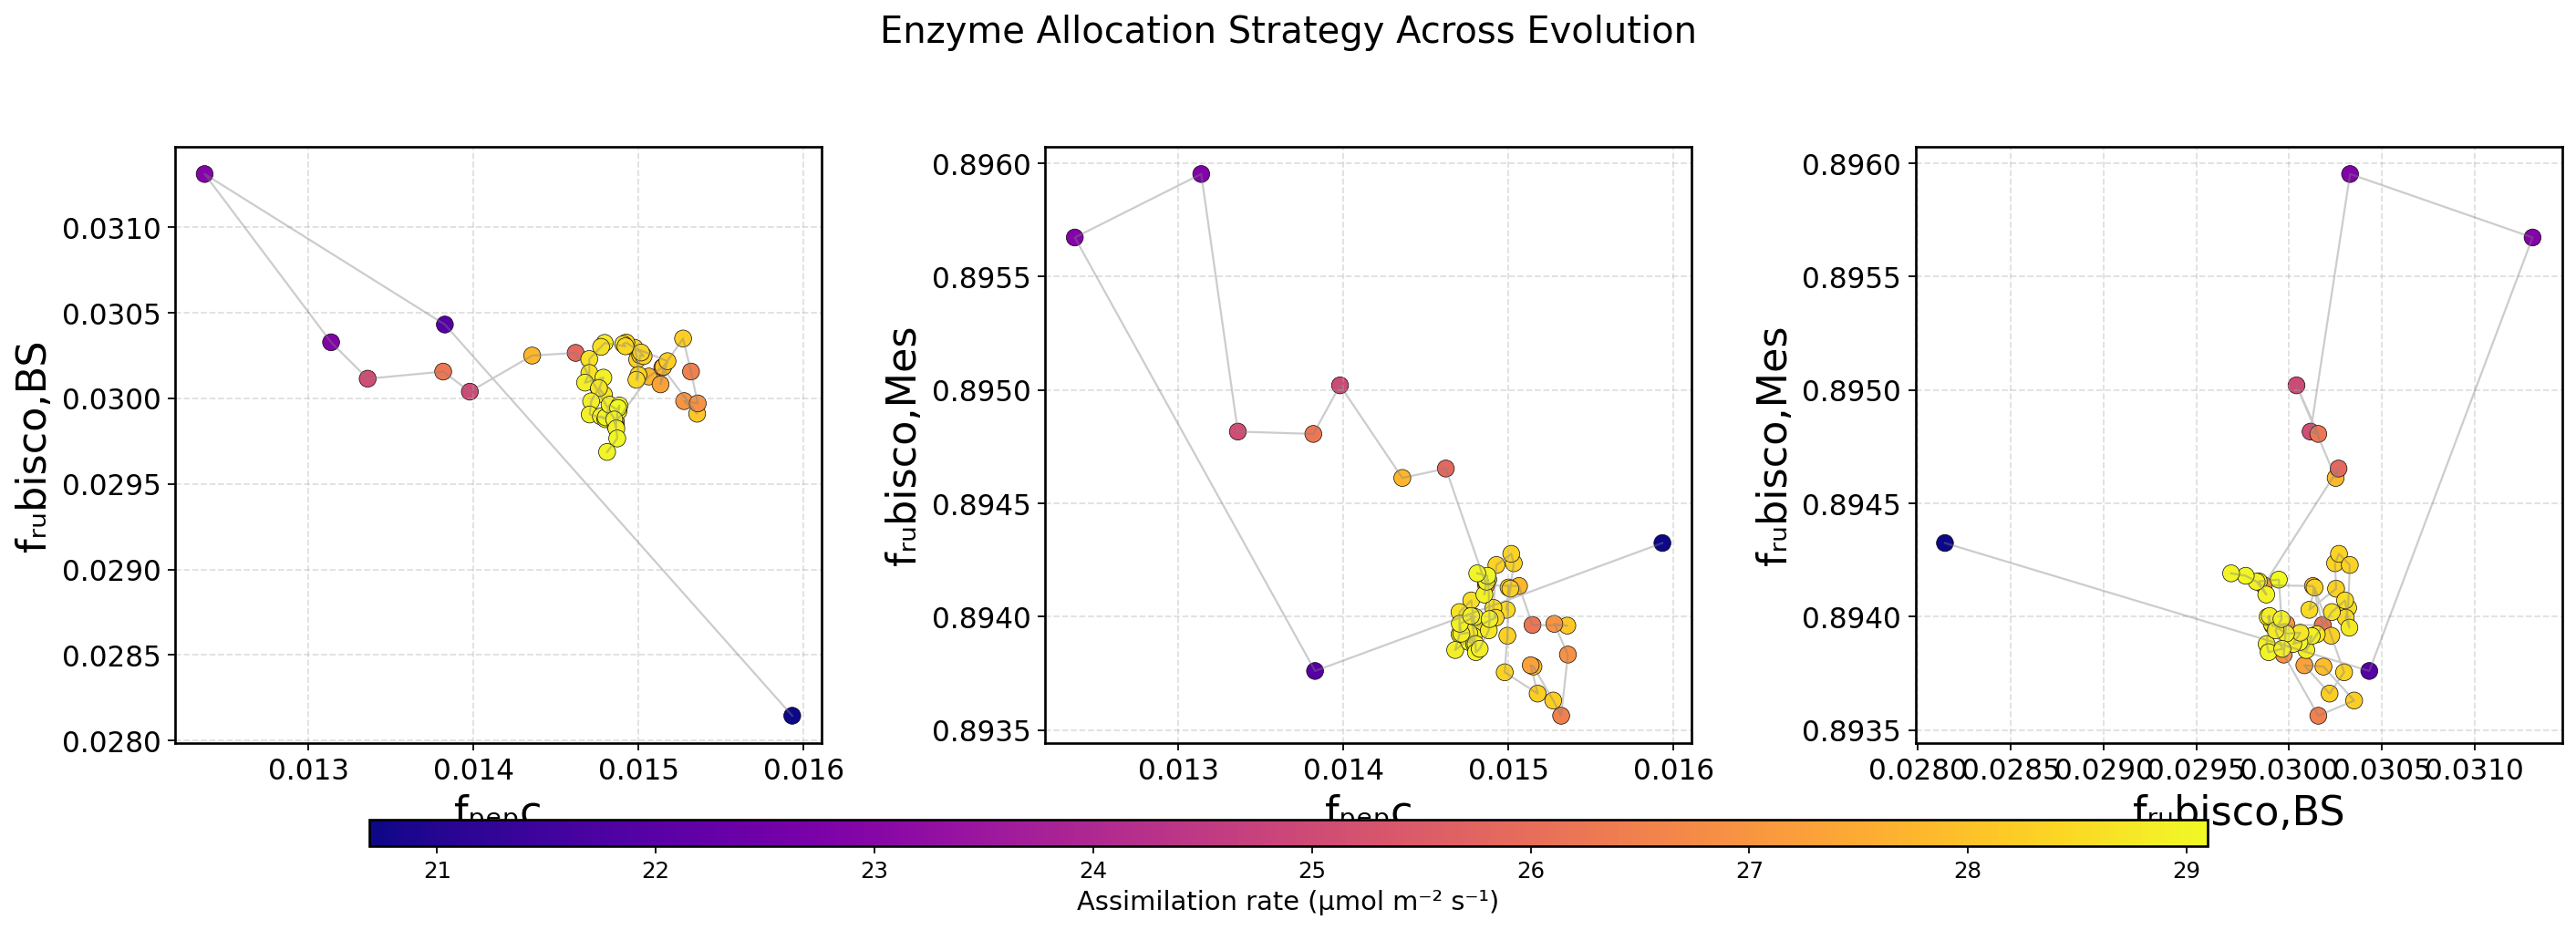

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:1060: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



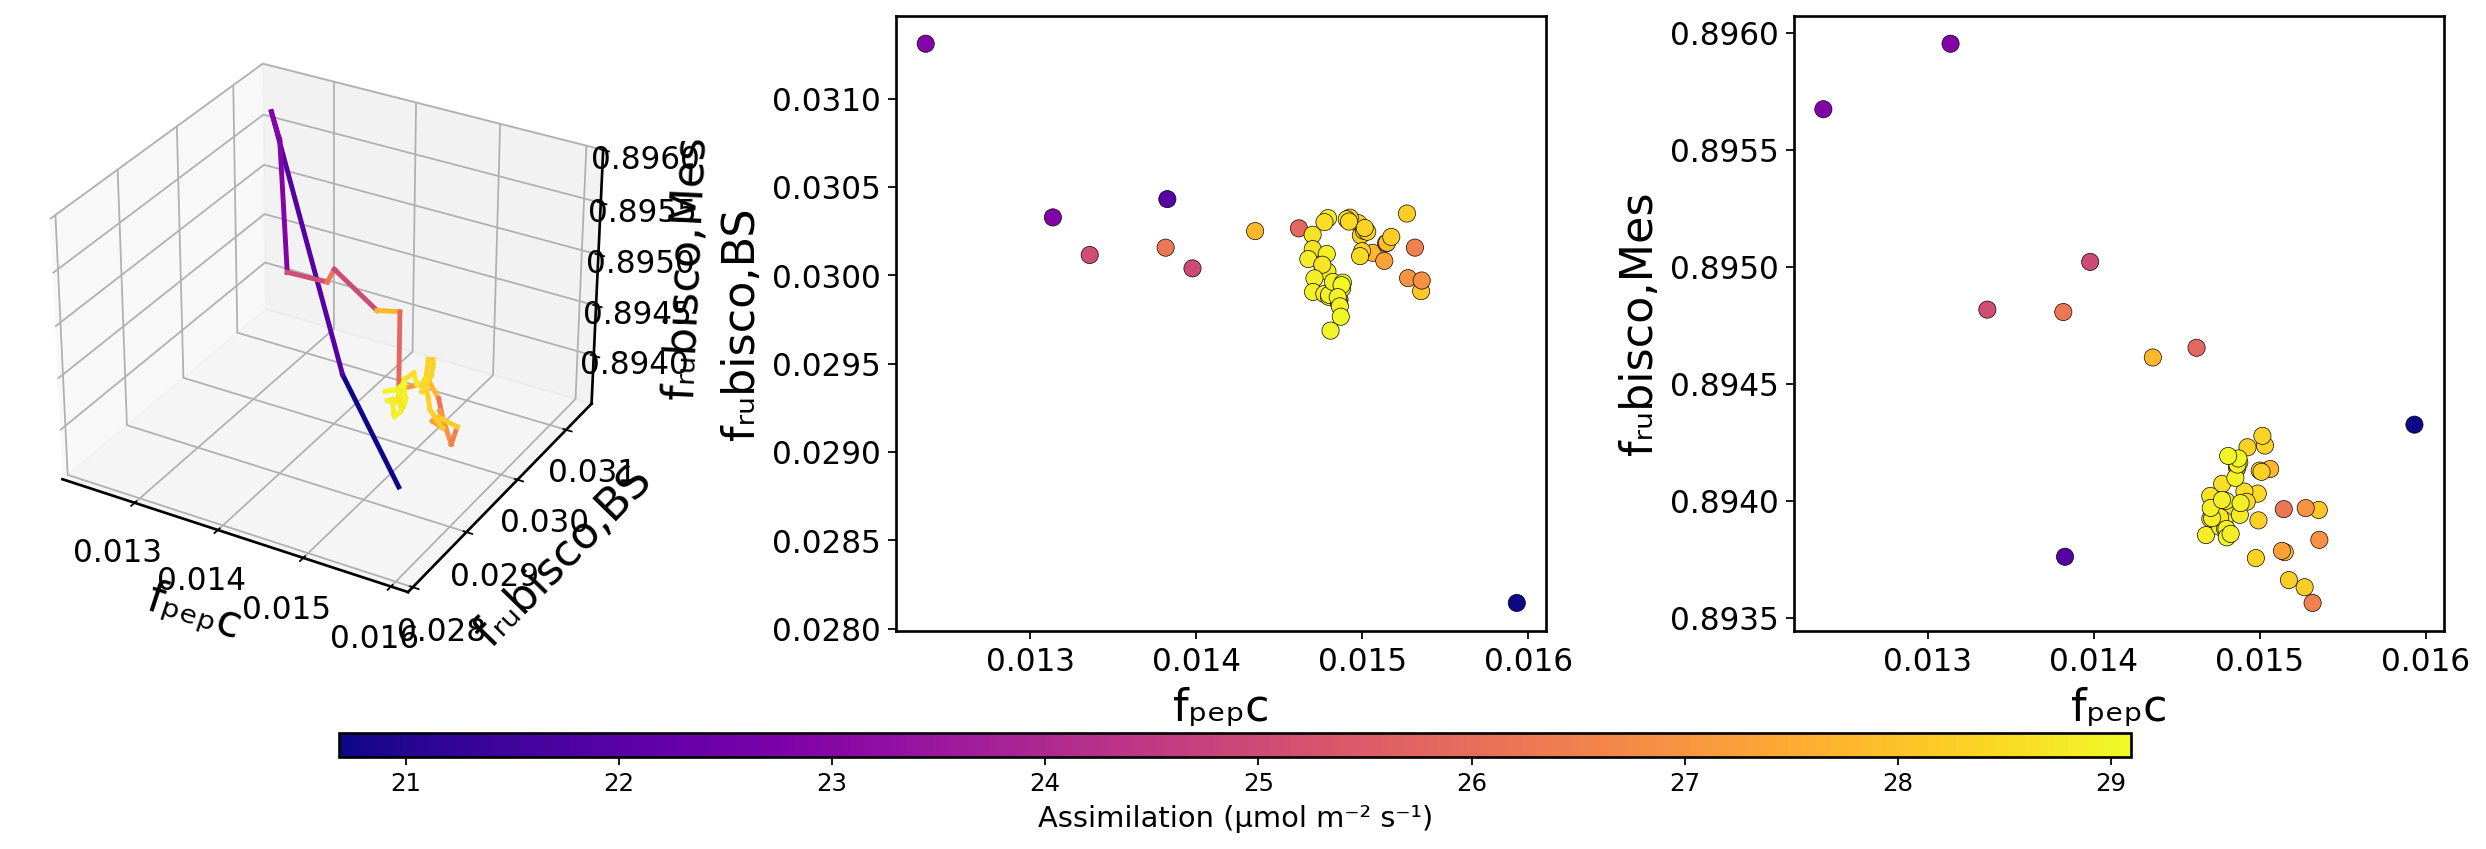

In [13]:
loaded_history = _sanitize_history(loaded_history)

plot_evolution_summary(loaded_history, save_path="plots/evolution/summary.png")
plot_3d_evolution_interactive(loaded_history, save_html="plots/evolution/evo_3d.html")
plot_hybrid_evolution_view(loaded_history, save_path="plots/evolution/hybrid_view.png")